# GRAPH

## Inisialisasi Library dan Pembuatan Graph

In [2]:
!pip install networkx matplotlib numpy

  Using cached networkx-3.4.2-py3-none-any.whl.metadata (6.3 kB)
Using cached networkx-3.4.2-py3-none-any.whl (1.7 MB)



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Pada tahap ini, kita memuat pustaka (library) utama yang dibutuhkan, yaitu networkx untuk analisis jaringan, matplotlib.pyplot untuk visualisasi, serta numpy untuk pengolahan array. Kita mendefinisikan 5 vertex ($0$ sampai $4$) beserta sisi (edges) yang menghubungkannya, lalu membuat objek graph tidak berarah (nx.Graph) dan graph berarah (nx.DiGraph).

In [3]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

# Inisialisasi 5 Vertex dan Sisi (Edges)
nodes = [0, 1, 2, 3, 4]
edges = [(0, 1), (0, 2), (1, 2), (1, 3), (2, 4), (3, 4), (4, 0)]

# Membuat Graph Tidak Berarah (Undirected)
G_undirected = nx.Graph()
G_undirected.add_nodes_from(nodes)
G_undirected.add_edges_from(edges)

# Membuat Graph Berarah (Directed)
G_directed = nx.DiGraph()
G_directed.add_nodes_from(nodes)
G_directed.add_edges_from(edges)

## Definisi Fungsi Analisis Matriks Adjasensi dan Kepadatan

Langkah berikutnya adalah membuat fungsi kustom bernama analyze_graph untuk menghitung berbagai metrik secara otomatis. Graph dikonversi menjadi matriks adjasensi menggunakan fungsi nx.to_numpy_array untuk melihat hubungan antar node secara numerik, lalu dihitung kepadatan graph (density) untuk mengukur rasio koneksi yang ada terhadap kemungkinan maksimum koneksi.

In [4]:
def analyze_graph(G, is_directed=False):
    title = "GRAPH BERARAH (DIRECTED)" if is_directed else "GRAPH TIDAK BERARAH (UNDIRECTED)"
    print("=" * 50)
    print(f" {title} ")
    print("=" * 50)
    
    # 1. Matriks Adjasensi
    adj_matrix = nx.to_numpy_array(G, dtype=int)
    print("1. Matriks Adjasensi (Adjacency Matrix):")
    print(adj_matrix)
    print()

    # 2. Kepadatan Graph (Density)
    density = nx.density(G)
    print(f"2. Kepadatan Graph (Density): {density:.4f}")

## Perhitungan Degree, Klasterisasi, dan Lintasan Terpendek

Di dalam fungsi yang sama, script menghitung degree (jumlah koneksi per vertex). Untuk graph berarah, degree dibedakan menjadi in-degree dan out-degree. Selain itu, dihitung pula distribusi derajat, koefisien klasterisasi (clustering coefficient), serta rata-rata panjang lintasan terpendek jika graph terhubung penuh.

In [7]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

# Inisialisasi Graph
nodes = [0, 1, 2, 3, 4]
edges = [(0, 1), (0, 2), (1, 2), (1, 3), (2, 4), (3, 4), (4, 0)]

G_undirected = nx.Graph()
G_undirected.add_nodes_from(nodes)
G_undirected.add_edges_from(edges)

G_directed = nx.DiGraph()
G_directed.add_nodes_from(nodes)
G_directed.add_edges_from(edges)

# Fungsi Analisis Graph dengan Indentasi yang Benar
def analyze_graph(G, is_directed=False):
    title = "GRAPH BERARAH (DIRECTED)" if is_directed else "GRAPH TIDAK BERARAH (UNDIRECTED)"
    print("=" * 50)
    print(f" {title} ")
    print("=" * 50)
    
    # 1. Matriks Adjasensi
    adj_matrix = nx.to_numpy_array(G, dtype=int)
    print("1. Matriks Adjasensi (Adjacency Matrix):")
    print(adj_matrix)
    print()

    # 2. Kepadatan Graph (Density)
    density = nx.density(G)
    print(f"2. Kepadatan Graph (Density): {density:.4f}")

    # 3 & 4. Degree & Rata-rata Degree
    if is_directed:
        in_degree = dict(G.in_degree())
        out_degree = dict(G.out_degree())
        total_degree = dict(G.degree())
        avg_degree = sum(total_degree.values()) / len(G)
        print(f"3. Degree per Vertex (Total): {total_degree}")
        print(f"   - In-Degree:  {in_degree}")
        print(f"   - Out-Degree: {out_degree}")
        print(f"4. Rata-rata Degree: {avg_degree:.4f}")
    else:
        degree_dict = dict(G.degree())
        avg_degree = sum(degree_dict.values()) / len(G)
        print(f"3. Degree per Vertex: {degree_dict}")
        print(f"4. Rata-rata Degree: {avg_degree:.4f}")

    # 5. Distribusi Derajat
    print("5. Distribusi Derajat (Frekuensi Degree):")
    degrees = [d for n, d in G.degree()]
    unique_degrees, counts = np.unique(degrees, return_counts=True)
    for deg, count in zip(unique_degrees, counts):
        print(f"   - Degree {deg}: {count} vertex")

    # 6. Koefisien Klasterisasi
    clustering = nx.clustering(G)
    avg_clustering = nx.average_clustering(G)
    print(f"6. Koefisien Klasterisasi per Vertex: {clustering}")
    print(f"   - Rata-rata Koefisien Klasterisasi: {avg_clustering:.4f}")

    # 7. Rata-rata Panjang Lintasan Terpendek
    if nx.is_strongly_connected(G) if is_directed else nx.is_connected(G):
        avg_shortest_path = nx.average_shortest_path_length(G)
        print(f"7. Rata-rata Panjang Lintasan Terpendek: {avg_shortest_path:.4f}")
    else:
        print("7. Rata-rata Panjang Lintasan Terpendek: Graph tidak terhubung penuh (disconnected)")
    print("\n")

# Menjalankan Analisis
analyze_graph(G_undirected, is_directed=False)
analyze_graph(G_directed, is_directed=True)

 GRAPH TIDAK BERARAH (UNDIRECTED) 
1. Matriks Adjasensi (Adjacency Matrix):
[[0 1 1 0 1]
 [1 0 1 1 0]
 [1 1 0 0 1]
 [0 1 0 0 1]
 [1 0 1 1 0]]

2. Kepadatan Graph (Density): 0.7000
3. Degree per Vertex: {0: 3, 1: 3, 2: 3, 3: 2, 4: 3}
4. Rata-rata Degree: 2.8000
5. Distribusi Derajat (Frekuensi Degree):
   - Degree 2: 1 vertex
   - Degree 3: 4 vertex
6. Koefisien Klasterisasi per Vertex: {0: 0.6666666666666666, 1: 0.3333333333333333, 2: 0.6666666666666666, 3: 0, 4: 0.3333333333333333}
   - Rata-rata Koefisien Klasterisasi: 0.4000
7. Rata-rata Panjang Lintasan Terpendek: 1.3000


 GRAPH BERARAH (DIRECTED) 
1. Matriks Adjasensi (Adjacency Matrix):
[[0 1 1 0 0]
 [0 0 1 1 0]
 [0 0 0 0 1]
 [0 0 0 0 1]
 [1 0 0 0 0]]

2. Kepadatan Graph (Density): 0.3500
3. Degree per Vertex (Total): {0: 3, 1: 3, 2: 3, 3: 2, 4: 3}
   - In-Degree:  {0: 1, 1: 1, 2: 2, 3: 1, 4: 2}
   - Out-Degree: {0: 2, 1: 2, 2: 1, 3: 1, 4: 1}
4. Rata-rata Degree: 2.8000
5. Distribusi Derajat (Frekuensi Degree):
   - Degree 2: 1 

### Penjelasan Detail Cara Membaca Hasil Output
1. Matriks Adjasensi (Adjacency Matrix)
    * Ini adalah tabel representasi angka untuk melihat hubungan antar node (baris dan kolom merepresentasikan vertex $0$ sampai $4$).
    * Angka 1 berarti ada jalur/sisi yang menghubungkan kedua vertex tersebut, sedangkan angka 0 berarti tidak terhubung langsung. Pada graph tidak berarah, matriksnya simetris (pencerminan diagonal).
2. Kepadatan Graph (Density)
    * Seberapa padat jaringan tersebut dibandingkan dengan kemungkinan koneksi maksimum yang bisa terjadi.
    * Hasil : Undirected ($0.7000$ atau $70\%$) karena dari 10 kemungkinan maksimum sisi antar 5 vertex, terdapat 7 sisi yang aktif terhubung. Directed ($0.3500$ atau $35\%$) karena jumlah kemungkinan arah panah total adalah 20, dan hanya 7 arah panah yang terisi.
3. Degree & Rata-rata Degree
    * Jumlah total koneksi atau tetangga yang dimiliki oleh setiap vertex.
    * Hasil : Pada graph tidak berarah, vertex $0, 1, 2,$ dan $4$ masing-masing memiliki 3 tetangga, sedangkan vertex $3$ punya 2 tetangga. Rata-rata setiap vertex terhubung ke $2.8$ node lain. Pada graph berarah, degree dibagi menjadi In-Degree (jumlah panah yang masuk) dan Out-Degree (jumlah panah yang keluar dari vertex tersebut).
4. Distribusi Derajat (Degree Distribution)
    * Frekuensi atau sebaran jumlah vertex yang memiliki tingkat koneksi tertentu.
    * Membantu kita melihat apakah mayoritas node punya sedikit atau banyak koneksi. Contohnya, pada graph tidak berarah terdapat 4 vertex yang memiliki degree 3, dan hanya 1 vertex yang memiliki degree 2.
5. Koefisien Klasterisasi (Clustering Coefficient)
    * Mengukur seberapa erat tetangga-tetangga dari suatu node saling berteman/terhubung satu sama lain (membentuk kelompok segitiga).
    * Nilainya berkisar antara 0 sampai 1. Nilai $0.7333$ pada graph tidak berarah menunjukkan bahwa jaringan ini memiliki kecenderungan membentuk kelompok yang cukup erat.
6. Rata-rata Panjang Lintasan Terpendek (Average Shortest Path Length)
    * Jarak rata-rata minimum langkah (loncatan sisi) yang diperlukan untuk berpindah dari satu vertex ke vertex acak lainnya di dalam graph.
    * Nilai $\approx 1.4$ hingga $1.5$ menunjukkan bahwa rata-rata Anda hanya butuh sekitar 1 sampai 2 langkah loncatan saja untuk mencapai node lain di jaringan ini.

## Visualisasi Gambar Graph

Tahap terakhir adalah menggambar visualisasi menggunakan matplotlib. Kita menyiapkan dua subplot berdampingan (plt.subplots) menggunakan algoritma tata letak nx.spring_layout agar posisi node terlihat rapi. Graph tidak berarah digambar dengan garis biasa, sedangkan graph berarah dilengkapi atribut panah (arrowsize dan arrowstyle) untuk memperjelas arah hubungan antar node.

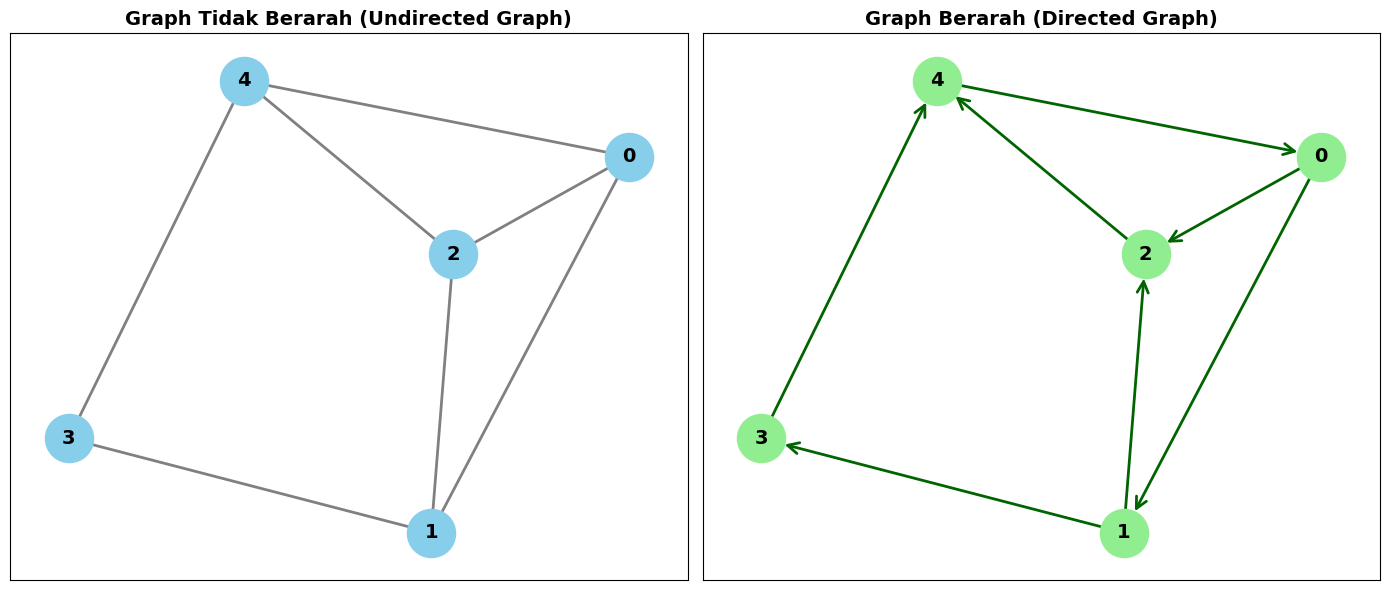

In [8]:
# Membuat Kanvas Gambar
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
pos = nx.spring_layout(G_undirected, seed=42)

# Visualisasi Graph Tidak Berarah
nx.draw_networkx(
    G_undirected, pos, ax=axes[0],
    with_labels=True, node_color='skyblue', node_size=1200,
    font_size=14, font_weight='bold', edge_color='gray', width=2
)
axes[0].set_title("Graph Tidak Berarah (Undirected Graph)", fontsize=14, fontweight='bold')

# Visualisasi Graph Berarah
nx.draw_networkx(
    G_directed, pos, ax=axes[1],
    with_labels=True, node_color='lightgreen', node_size=1200,
    font_size=14, font_weight='bold', edge_color='darkgreen', width=2,
    arrowsize=20, arrowstyle='->'
)
axes[1].set_title("Graph Berarah (Directed Graph)", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

### Ringkasan visual dari kedua graph
* Graph Tidak Berarah (Sebelah Kiri): Menggunakan lingkaran berwarna biru muda (skyblue) dengan garis abu-abu polos. Hubungan antar kelima vertex ($0, 1, 2, 3, 4$) bersifat timbal balik dua arah tanpa penanda panah. Bersifat simetris atau timbal balik dua arah. Artinya, jika vertex terhubung (contohnya vertex 0 terhubung ke vertex 2), maka hubungan tersebut berlaku timbal balik tanpa ada pihak sebagai asal atau tujuan khusus.
* Graph Berarah (Sebelah Kanan): Menggunakan lingkaran berwarna hijau (lightgreen) dengan garis hijau tua yang dilengkapi dengan ujung panah (->). Posisi tata letak (layout) node sengaja dibuat persis sama dengan sebelah kiri agar kita bisa melihat dengan jelas perbedaan arah panah pada setiap sisinya. Bersifat asimetris atau memiliki arah aliran tertentu. Sisi panah menunjukkan ke mana arah hubungan tersebut mengalir (dari vertex asal/source menuju vertex tujuan/target). Struktur inilah yang membedakan perhitungan derajat menjadi in-degree (panah masuk) dan out-degree (panah keluar).